# Q12 — Kernel PCA on a Nonlinear Dataset

**Aim:** Apply Kernel PCA to a nonlinear dataset and visualize whether a nonlinear mapping reveals its structure. This notebook uses the `make_moons` dataset and compares ordinary PCA with RBF Kernel PCA.

**Parameter study:** Change `gamma`, kernel type, and polynomial degree; compare scatter plots and a label-based silhouette diagnostic. Kernel PCA itself is unsupervised; labels are used only to evaluate the embedding afterward.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.svm import SVC

RANDOM_STATE = 42
X, y = make_moons(n_samples=600, noise=0.08, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Dataset:", X.shape, "| train:", X_train.shape, "| test:", X_test.shape)

Dataset: (600, 2) | train: (450, 2) | test: (150, 2)


## 1. Visualize the original nonlinear data

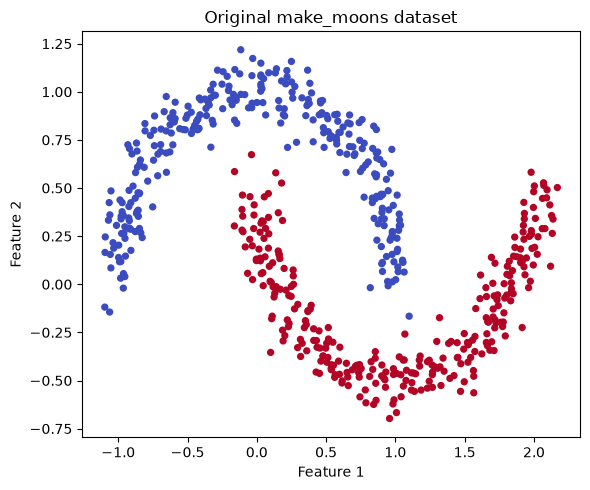

In [2]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=18)
plt.title("Original make_moons dataset")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.tight_layout(); plt.show()

## 2. Compare ordinary PCA and RBF Kernel PCA

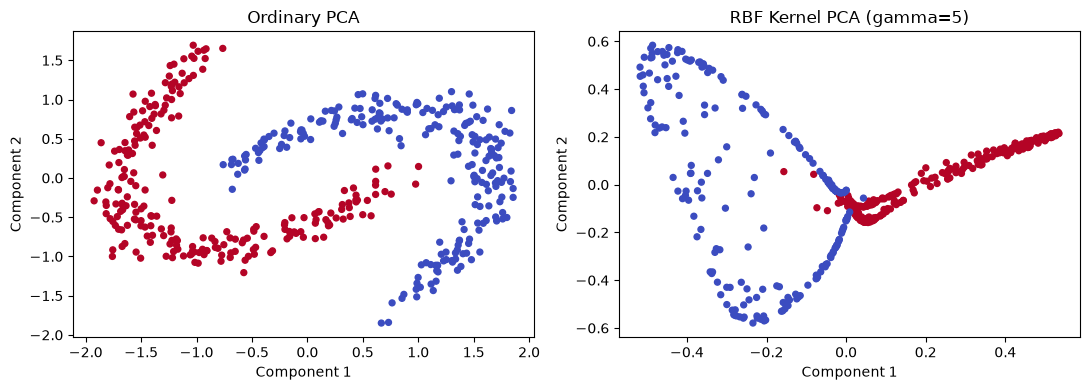

PCA explained variance ratio: [0.70732858 0.29267142]


In [3]:
pca = PCA(n_components=2)
Z_pca = pca.fit_transform(X_train_scaled)
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=5, eigen_solver="arpack")
Z_kpca = kpca.fit_transform(X_train_scaled)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(Z_pca[:, 0], Z_pca[:, 1], c=y_train, cmap="coolwarm", s=18)
axes[0].set_title("Ordinary PCA")
axes[1].scatter(Z_kpca[:, 0], Z_kpca[:, 1], c=y_train, cmap="coolwarm", s=18)
axes[1].set_title("RBF Kernel PCA (gamma=5)")
for ax in axes:
    ax.set_xlabel("Component 1"); ax.set_ylabel("Component 2")
plt.tight_layout(); plt.show()
print("PCA explained variance ratio:", pca.explained_variance_ratio_)

## 3. Parameter experiment A — change RBF gamma

`gamma` controls the locality of the RBF similarity function. Smaller gamma creates a smoother, broader similarity; larger gamma makes similarity more localized. Compare both the embeddings and the diagnostic score.

,gamma,Label silhouette (diagnostic)
0,0.1,0.3764
1,0.5,0.3555
2,1.0,0.3384
3,2.0,0.3611
4,5.0,0.3022
5,10.0,0.2432
6,20.0,0.1343


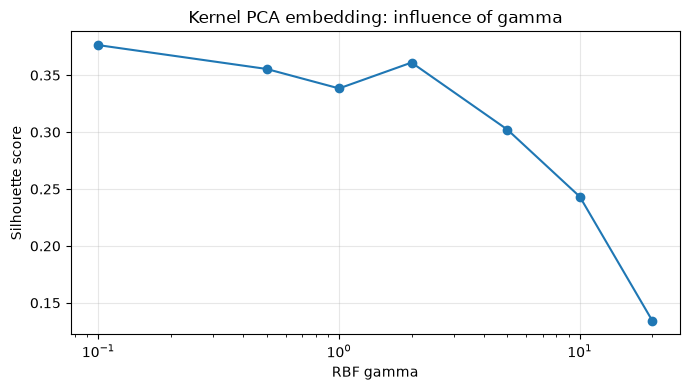

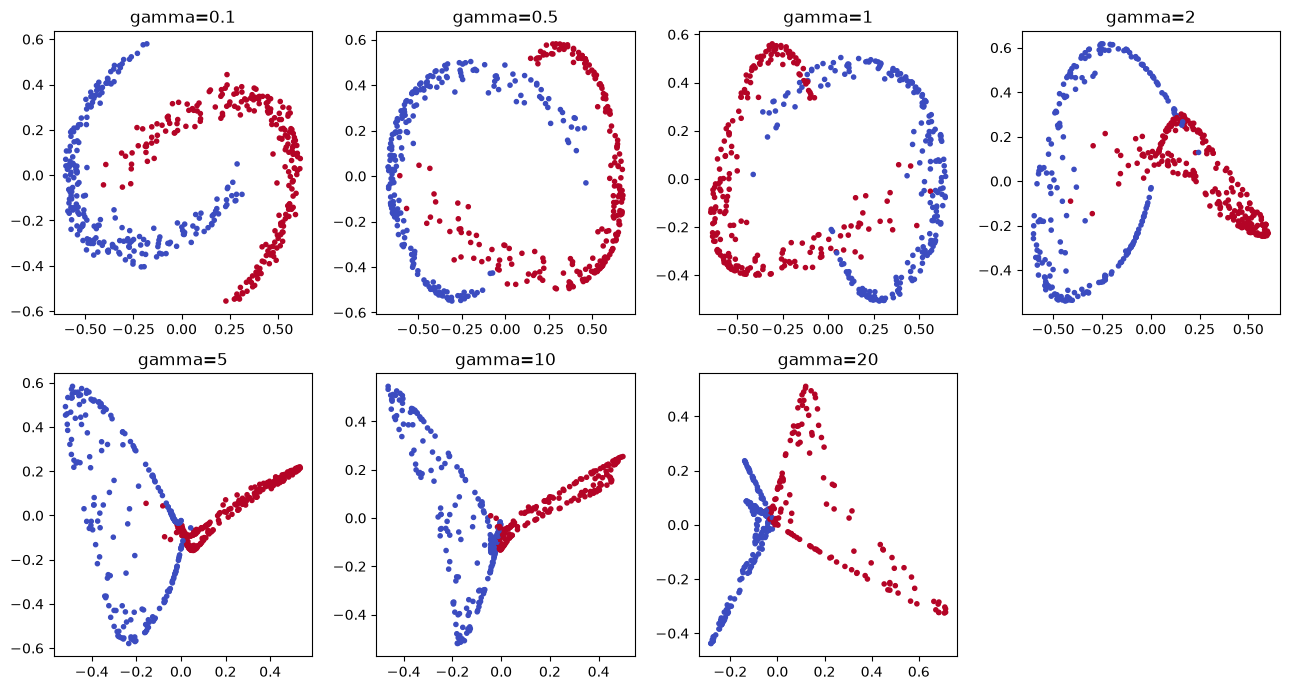

In [4]:
gammas = [0.1, 0.5, 1, 2, 5, 10, 20]
gamma_rows, gamma_embeddings = [], {}
for gamma in gammas:
    model = KernelPCA(n_components=2, kernel="rbf", gamma=gamma, eigen_solver="arpack")
    Z = model.fit_transform(X_train_scaled)
    gamma_embeddings[gamma] = Z
    gamma_rows.append({"gamma": gamma, "Label silhouette (diagnostic)": silhouette_score(Z, y_train)})
gamma_results = pd.DataFrame(gamma_rows)
display(gamma_results.round(4))
plt.figure(figsize=(7, 4))
plt.plot(gamma_results["gamma"], gamma_results["Label silhouette (diagnostic)"], marker="o")
plt.xscale("log"); plt.xlabel("RBF gamma"); plt.ylabel("Silhouette score")
plt.title("Kernel PCA embedding: influence of gamma")
plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, gamma in zip(axes.ravel(), gammas):
    Z = gamma_embeddings[gamma]
    ax.scatter(Z[:, 0], Z[:, 1], c=y_train, cmap="coolwarm", s=9)
    ax.set_title(f"gamma={gamma}")
for ax in axes.ravel()[len(gammas):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Interpretation:** Use the plots and silhouette scores together. A higher score suggests better separation of the known labels in this embedding, but it is only a diagnostic and not a guarantee of downstream model performance.

## 4. Parameter experiment B — compare kernel type and polynomial degree

,Setting,Label silhouette (diagnostic)
0,{'kernel': 'linear'},0.3762
1,"{'kernel': 'rbf', 'gamma': 0.5}",0.3555
2,"{'kernel': 'rbf', 'gamma': 2}",0.3611
3,"{'kernel': 'rbf', 'gamma': 5}",0.3022
4,"{'kernel': 'poly', 'gamma': 1, 'degree': 2}",0.3291
5,"{'kernel': 'poly', 'gamma': 1, 'degree': 3}",0.3272
6,"{'kernel': 'poly', 'gamma': 1, 'degree': 4}",0.3066


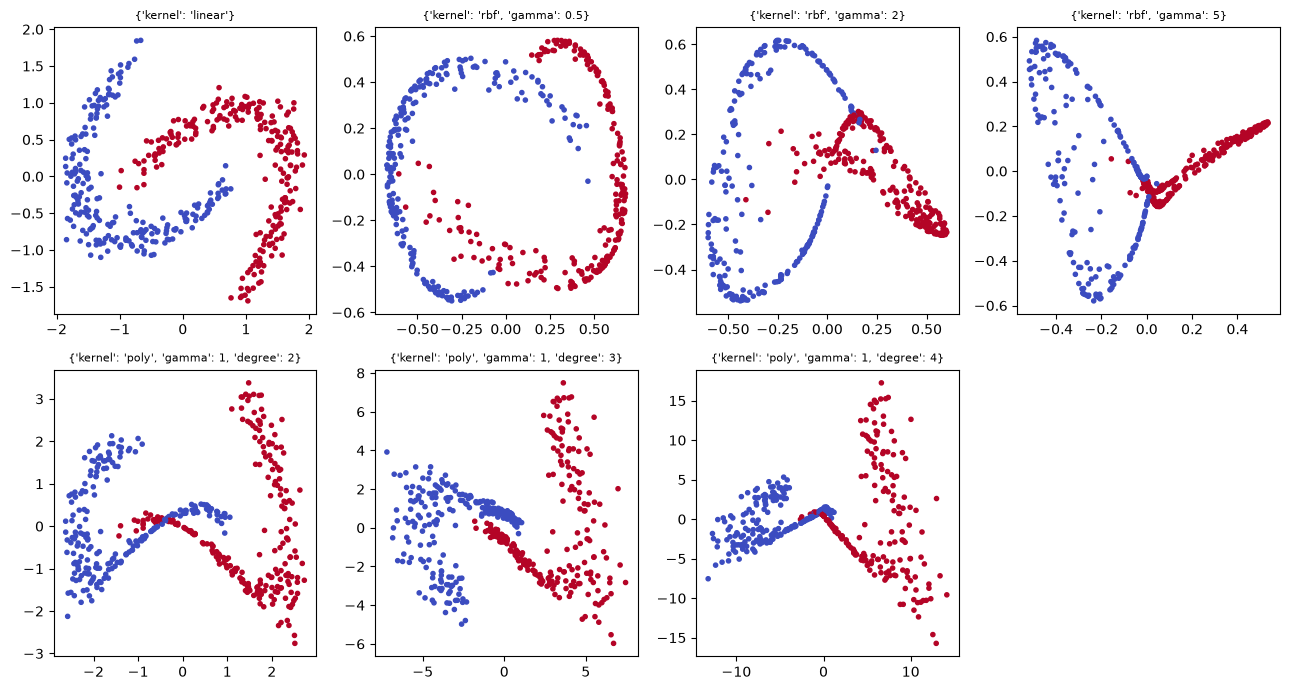

In [5]:
settings = [
    {"kernel": "linear"},
    {"kernel": "rbf", "gamma": 0.5},
    {"kernel": "rbf", "gamma": 2},
    {"kernel": "rbf", "gamma": 5},
    {"kernel": "poly", "gamma": 1, "degree": 2},
    {"kernel": "poly", "gamma": 1, "degree": 3},
    {"kernel": "poly", "gamma": 1, "degree": 4},
]
kernel_rows, kernel_embeddings = [], {}
for setting in settings:
    kwargs = {"n_components": 2, "kernel": setting["kernel"], "eigen_solver": "arpack"}
    if "gamma" in setting: kwargs["gamma"] = setting["gamma"]
    if "degree" in setting: kwargs["degree"] = setting["degree"]
    model = KernelPCA(**kwargs)
    Z = model.fit_transform(X_train_scaled)
    label = str(setting)
    kernel_embeddings[label] = Z
    kernel_rows.append({"Setting": label, "Label silhouette (diagnostic)": silhouette_score(Z, y_train)})
kernel_results = pd.DataFrame(kernel_rows)
display(kernel_results.round(4))
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, (label, Z) in zip(axes.ravel(), kernel_embeddings.items()):
    ax.scatter(Z[:, 0], Z[:, 1], c=y_train, cmap="coolwarm", s=9)
    ax.set_title(label, fontsize=8)
for ax in axes.ravel()[len(kernel_embeddings):]: ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Optional downstream classification check

Kernel PCA is dimensionality reduction, not a classifier. This optional test compares an RBF-SVM on original standardized features with an RBF-SVM trained on the two-dimensional Kernel PCA representation.

In [6]:
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=5, eigen_solver="arpack")
Z_train = kpca.fit_transform(X_train_scaled)
Z_test = kpca.transform(X_test_scaled)

svm_original = SVC(kernel="rbf", random_state=RANDOM_STATE)
svm_original.fit(X_train_scaled, y_train)
pred_original = svm_original.predict(X_test_scaled)

svm_kpca = SVC(kernel="rbf", random_state=RANDOM_STATE)
svm_kpca.fit(Z_train, y_train)
pred_kpca = svm_kpca.predict(Z_test)

print("SVM on original features accuracy:", round(accuracy_score(y_test, pred_original), 4))
print("SVM after Kernel PCA accuracy:", round(accuracy_score(y_test, pred_kpca), 4))

SVM on original features accuracy: 0.9933
SVM after Kernel PCA accuracy: 0.9467


## 6. Conclusion checklist
- Describe the nonlinear shape of `make_moons`.
- Compare ordinary PCA and Kernel PCA plots.
- Explain the effect of RBF `gamma`.
- Compare linear, RBF, and polynomial kernels.
- Clarify that silhouette is a diagnostic and the optional accuracy belongs to the SVM classification task.